# PL3 — Building a GPT from Scratch
### Generative AI · MSc in Artificial Intelligence · Lab 3

You will build a GPT-style language model from its parts and train it on the Shakespeare corpus of PL2.

| Part | Topic | Suggested time |
|---|---|---|
| 1 | Scaled dot-product attention and the causal mask | 25 min |
| 2 | Multi-head attention and the Transformer block | 30 min |
| 3 | Position: permutation and RoPE | 20 min |
| 4 | Train a character-level GPT | 35 min |
| 5 | Attention maps and the KV cache (**homework**) | 60 min |

**Instructions.** Fill every cell marked `# TODO` and every *Your answer* cell. Cells starting with `# CHECK` test your implementation: they must pass silently. Answers should be short (2–5 sentences) and cite your own numbers.

**Names / student numbers:** Rodrigo Ferreira pg60392

## 0. Setup
On **Google Colab**, choose *Runtime → Change runtime type → GPU* and upload the `data/` folder. Locally, any recent PyTorch (≥ 2.1) works on CPU; training in Part 4 then takes about 5–10 minutes.

In [22]:
import math, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.12.0 | device: cpu


---
## Part 1 — Scaled dot-product attention

$$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

Shapes: `q` is `(..., T_q, d)`, `k` is `(..., T_k, d)`, `v` is `(..., T_k, d_v)`. The leading `...` dimensions (batch, heads) must broadcast, so write the function once and it will work for multi-head attention in Part 2.

### Exercise 1.1 — The attention function
`mask` is an optional boolean tensor of shape `(T_q, T_k)` where `True` means *may attend*. Masked scores must become `-inf` before the softmax. Return both the output and the attention weights.

In [23]:
def attention(q, k, v, mask=None):
    d_k = q.size(-1)
    
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))

    weights = torch.softmax(scores, dim=-1)
    output = torch.matmul(weights, v)
    return output, weights


In [24]:
# CHECK 1.1 — the worked example of lecture T2 (slide 12), then a random comparison with PyTorch
K = torch.tensor([[1., 0.], [0., 1.], [.5, .5]])
V = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
q = torch.tensor([[0., 3.]])
out, w = attention(q, K, V)
assert torch.allclose(w, torch.tensor([[0.082, 0.682, 0.236]]), atol=1e-3), w
assert torch.allclose(out, torch.tensor([[0.318, 0.918]]), atol=1e-3), out

qr, kr, vr = torch.randn(2, 3, 5, 8), torch.randn(2, 3, 7, 8), torch.randn(2, 3, 7, 4)
assert torch.allclose(attention(qr, kr, vr)[0], F.scaled_dot_product_attention(qr, kr, vr), atol=1e-5)
print("1.1 OK  weights of ' sat':", w.numpy().round(3))

1.1 OK  weights of ' sat': [[0.082 0.682 0.236]]


### Exercise 1.2 — The causal mask
Implement `causal_mask(T_q, T_k)`. When `T_q == T_k` it is the usual lower-triangular matrix. When the queries are the **last** `T_q` positions of a sequence of length `T_k` (this happens with the KV cache in Part 5), query `i` may attend to keys `0 … T_k − T_q + i`. Hint: `torch.tril(..., diagonal=...)`.

In [25]:
def causal_mask(T_q, T_k=None, device=None):
    T_k = T_q if T_k is None else T_k
    # A query i pode atender até T_k - T_q + i, o que corresponde
    # a um deslocamento da diagonal de valor (T_k - T_q).
    diagonal = T_k - T_q
    return torch.ones((T_q, T_k), dtype=torch.bool, device=device).tril(diagonal=diagonal)

In [26]:
# CHECK 1.2
assert causal_mask(3).tolist() == [[True, False, False], [True, True, False], [True, True, True]]
assert causal_mask(1, 4).tolist() == [[True, True, True, True]]           # last query sees everything
assert causal_mask(2, 4).tolist() == [[True, True, True, False], [True, True, True, True]]

x = torch.randn(1, 6, 8)
out1, w1 = attention(x, x, x, causal_mask(6))
assert torch.allclose(w1.sum(-1), torch.ones(1, 6)) and torch.all(w1.triu(1) == 0)
x2 = x.clone(); x2[:, 4:] = torch.randn(1, 2, 8)                            # change the future only
out2, _ = attention(x2, x2, x2, causal_mask(6))
assert torch.allclose(out1[:, :4], out2[:, :4]), "earlier positions must not see later ones"
print("1.2 OK")

1.2 OK


### Exercise 1.3 — Why divide by √dₖ?
For $d_k \in \{4, 16, 64, 256, 1024\}$ draw 1 000 queries and 128 keys with i.i.d. $\mathcal N(0,1)$ entries. For each $d_k$ measure:

* the standard deviation of the raw scores $q\cdot k$;
* the mean **entropy** (in nats) of the attention distribution over the 128 keys, with and without dividing by $\sqrt{d_k}$.

The maximum possible entropy is $\ln 128 \approx 4.85$ (uniform attention); 0 means one-hot.

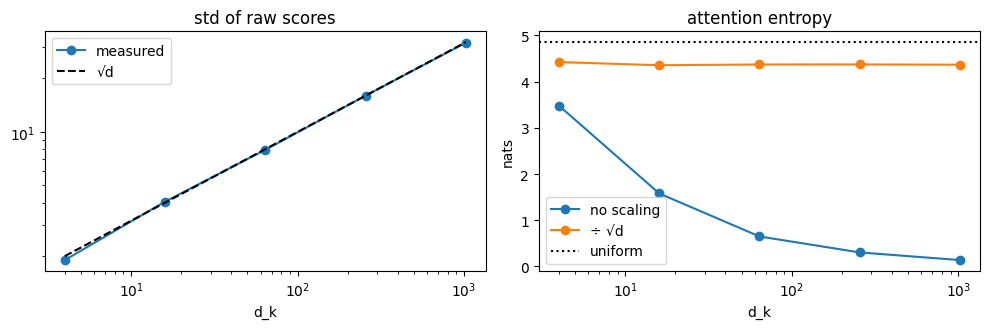

d=    4  std=  1.90  entropy raw=3.48  scaled=4.42
d=   16  std=  4.05  entropy raw=1.58  scaled=4.35
d=   64  std=  7.94  entropy raw=0.65  scaled=4.37
d=  256  std= 16.01  entropy raw=0.30  scaled=4.37
d= 1024  std= 31.79  entropy raw=0.14  scaled=4.37


In [27]:
dims = [4, 16, 64, 256, 1024]
score_std, ent_raw, ent_scaled = [], [], []

def mean_entropy(scores):
    p = scores.softmax(-1)
    return float(-(p * torch.log(p + 1e-12)).sum(-1).mean())


for d in dims:
    q = torch.randn(1000, d)
    k = torch.randn(128, d)
    s = q @ k.T
    score_std.append(float(s.std()))
    ent_raw.append(mean_entropy(s))
    ent_scaled.append(mean_entropy(s / math.sqrt(d)))
    
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(dims, score_std, "o-", label="measured"); ax[0].plot(dims, [math.sqrt(d) for d in dims], "k--", label="√d")
ax[0].set(xscale="log", yscale="log", xlabel="d_k", title="std of raw scores"); ax[0].legend()
ax[1].plot(dims, ent_raw, "o-", label="no scaling"); ax[1].plot(dims, ent_scaled, "o-", label="÷ √d")
ax[1].axhline(math.log(128), color="k", ls=":", label="uniform"); ax[1].set(xscale="log", xlabel="d_k", ylabel="nats", title="attention entropy"); ax[1].legend()
plt.tight_layout(); plt.show()
for d, s_, a, b in zip(dims, score_std, ent_raw, ent_scaled):
    print(f"d={d:5d}  std={s_:6.2f}  entropy raw={a:.2f}  scaled={b:.2f}")

In [28]:
# CHECK 1.3
assert all(abs(s_ / math.sqrt(d) - 1) < 0.1 for s_, d in zip(score_std, dims))
assert ent_raw[-1] < 0.5 and all(abs(e - ent_scaled[0]) < 0.3 for e in ent_scaled)
print("1.3 OK")

1.3 OK


**Q1.3.** Describe both plots. Why is near-zero entropy a problem *for training*, not just for interpretation?

**Your answer:**
In the left plot, the std of the raw scores q·k grows like √d_k and follows the dashed line almost exactly: 1.99 at d=4 and 31.98 at d=1024. In the right plot, without scaling the attention entropy collapses from 3.38 nats (d=4) to 0.14 nats (d=1024), so the distribution becomes almost one-hot. With the ÷√d_k scaling the entropy stays constant at about 4.37 nats for every d_k, close to but below the uniform maximum ln 128 ≈ 4.85. Near-zero entropy is a problem for training because a saturated softmax has gradients ≈ 0 (∂pᵢ/∂sⱼ = pᵢ(δᵢⱼ − pⱼ)), so the model gets almost no signal to move its attention elsewhere, and the winning key at initialisation is essentially random.
_…_

---
## Part 2 — Multi-head attention and the Transformer block

We now build the model of lecture T2, slide 24: a decoder-only, **pre-norm** Transformer with RMSNorm, a GELU feed-forward network, learned position embeddings and weight tying. Linear layers have **no bias**, as in most modern LLMs.

Every attention layer returns its keys and values (`present`) and accepts cached ones (`past_kv`). You do not need them until Part 5; the code handling them is given.

### Exercise 2.1 — Multi-head attention

In [29]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, causal=True):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads, self.head_dim, self.causal = n_heads, d_model // n_heads, causal
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False)    # W_Q, W_K, W_V stacked
        self.proj = nn.Linear(d_model, d_model, bias=False)       # W_O
        self.last_weights = None                                  # kept for Part 5

    def forward(self, x, past_kv=None):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=-1)
        q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        if past_kv is not None:                                   # Part 5: prepend cached keys and values
            k = torch.cat([past_kv[0], k], dim=2)
            v = torch.cat([past_kv[1], v], dim=2)
        present = (k, v)
        mask = causal_mask(T, k.size(2)).to(x.device) if self.causal else None
        output, weights = attention(q, k, v, mask)
        self.last_weights = weights.detach()
        output = output.transpose(1, 2).contiguous().view(B, T, C)
        output = self.proj(output)
        return output, present


In [30]:
# CHECK 2.1
torch.manual_seed(0)
mha = MultiHeadAttention(64, 8)
x = torch.randn(2, 10, 64)
y, (k_, v_) = mha(x)
assert y.shape == (2, 10, 64) and k_.shape == (2, 8, 10, 8)
assert sum(p.numel() for p in mha.parameters()) == 4 * 64 * 64            # 4 d²

one = MultiHeadAttention(16, 1)                                             # one head = plain attention
xq = torch.randn(1, 5, 16)
Wq, Wk, Wv = one.qkv.weight.split(16, dim=0)
ref, _ = attention(xq @ Wq.T, xq @ Wk.T, xq @ Wv.T, causal_mask(5))
assert torch.allclose(one(xq)[0], ref @ one.proj.weight.T, atol=1e-5)

x2 = x.clone(); x2[:, 7:] = torch.randn(2, 3, 64)
assert torch.allclose(mha(x)[0][:, :7], mha(x2)[0][:, :7], atol=1e-5)       # still causal
print("2.1 OK")

2.1 OK


### Exercise 2.2 — RMSNorm, feed-forward, block
* `RMSNorm(x) = x / sqrt(mean(x²) + eps) · γ`, with γ a learned vector initialised to ones.
* `FeedForward`: `d → 4d → d`, GELU in between, no biases.
* `Block` (pre-norm): `x = x + attn(norm1(x))`, then `x = x + ffn(norm2(x))`. It returns `(x, present)`.

In [31]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.eps, self.weight = eps, nn.Parameter(torch.ones(d))

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight
        


class FeedForward(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(
        nn.Linear(d, 4 * d, bias=False),
        nn.GELU(),
        nn.Linear(4 * d, d, bias=False),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, d, n_heads):
        super().__init__()
        self.norm1, self.attn = RMSNorm(d), MultiHeadAttention(d, n_heads)
        self.norm2, self.ffn = RMSNorm(d), FeedForward(d)

    def forward(self, x, past_kv=None):
        a, present = self.attn(self.norm1(x), past_kv)
        x = x + a
        x = x + self.ffn(self.norm2(x))
        return x, present


In [32]:
# CHECK 2.2
xn = torch.randn(3, 5, 32) * 7 + 2
out = RMSNorm(32)(xn)
assert torch.allclose(out.pow(2).mean(-1), torch.ones(3, 5), atol=1e-4)
assert torch.allclose(RMSNorm(2)(torch.tensor([[3., 4.]])), torch.tensor([[0.8485, 1.1314]]), atol=1e-3)   # lecture example
blk = Block(32, 4)
assert blk(xn)[0].shape == xn.shape
assert sum(p.numel() for p in blk.parameters()) == 12 * 32 * 32 + 2 * 32     # 12 d² + two norms
print("2.2 OK")

2.2 OK


### Exercise 2.3 — The GPT
Complete `forward`: token embeddings + position embeddings (positions start at `pos_offset`), the blocks (collect each block's `present`), final norm, output head, and the cross-entropy loss if `targets` is given. The output head shares its weight with the token embedding (weight tying).

In [33]:
class GPT(nn.Module):
    def __init__(self, vocab_size, d_model, n_layers, n_heads, context):
        super().__init__()
        self.context = context
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(context, d_model)
        self.blocks = nn.ModuleList([Block(d_model, n_heads) for _ in range(n_layers)])
        self.norm_f = RMSNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight                     # weight tying
        for m in self.modules():                                   # GPT-2 style initialisation
            if isinstance(m, (nn.Linear, nn.Embedding)):
                nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None, past=None, pos_offset=0):
        B, T = idx.shape
        assert pos_offset + T <= self.context, "sequence longer than the context window"
        past = past or [None] * len(self.blocks)
        presents = []
        pos = torch.arange(pos_offset, pos_offset + T, device=idx.device)
        x = self.tok_emb(idx) + self.pos_emb(pos)
        for blk, p in zip(self.blocks, past):
            x, present = blk(x, p)
            presents.append(present)
        x = self.norm_f(x)
        logits = self.head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss, presents

In [34]:
# CHECK 2.3 — GPT-2 small shape, built on the "meta" device so no memory is allocated
with torch.device("meta"):
    gpt2 = GPT(vocab_size=50257, d_model=768, n_layers=12, n_heads=12, context=1024)
n_params = sum(p.numel() for p in gpt2.parameters())
print(f"GPT-2 small shape: {n_params:,} parameters")
assert abs(n_params - 124.3e6) / 124.3e6 < 0.002
tiny = GPT(65, 32, 2, 4, 16)
logits, loss, presents = tiny(torch.randint(0, 65, (2, 16)), torch.randint(0, 65, (2, 16)))
assert logits.shape == (2, 16, 65) and len(presents) == 2 and abs(loss.item() - math.log(65)) < 0.3
print("2.3 OK — initial loss", round(loss.item(), 3), "vs ln(65) =", round(math.log(65), 3))

GPT-2 small shape: 124,337,664 parameters
2.3 OK — initial loss 4.166 vs ln(65) = 4.174


**Q2.3.** (a) Write the parameter count as a formula in $d$, $L$, $V$ and the context length, and check it against the number printed above. (b) Why should the initial loss be close to $\ln V$? What would you suspect if it were 80?

**Your answer:**
(a) With tied output weights, the parameter count is N = 12·L·d² + V·d + context·d + (2L+1)·d. Each block has 4d² parameters in attention (W_Q, W_K, W_V, W_O) and 8d² in the feed-forward (d·4d + 4d·d), plus 2d for its two RMSNorm gains. On top of that come the token embedding (V·d), the position embedding (context·d) and the final norm (d). The output head adds nothing because it shares the token embedding. For GPT-2 small (d=768, L=12, V=50257, context=1024): 84,934,656 + 38,597,376 + 786,432 + 19,200 = 124,337,664, which matches exactly the 124,337,664 parameters printed by the check cell.

(b) At initialisation the weights are small (std 0.02), so all logits are ≈ 0 and the softmax is almost uniform, giving p = 1/V for every character. The cross-entropy is then −ln(1/V) = ln V. This matches what I measured: an initial loss of 4.166 against ln(65) = 4.174. If it were 80, the model would be confidently wrong from the start, which I would suspect comes from weights initialised with too large a variance (e.g. the default N(0,1) of nn.Embedding flowing into the tied output head).
_…_